# 0. setup & earlier steps

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import pdist
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

In [3]:
load_dotenv()   # finds the .env in the repo root, also from citibike/notebooks/

engine = create_engine(
    "postgresql+psycopg://",
    connect_args={
        "host": "100.88.194.89",
        "port": 5432,
        "dbname": "citibike",
        "user": os.environ["CITIBIKE_DB_USER"],
        "password": os.environ["CITIBIKE_DB_PASSWORD"].strip(),
        "connect_timeout": 10,
    },
)

with engine.connect() as conn:
    print("Connected as", conn.execute(text("SELECT current_user")).scalar())

Connected as r0957896


In [4]:
def fmt(value, spec: str = ",") -> str:
    """Format a number with a dot as thousands separator and a comma as decimal separator: 212.310.903 / 0,057."""
    return f"{value:{spec}}".translate(str.maketrans(",.", ".,"))


def sql(query: str, **params) -> pd.DataFrame:
    t0 = time.time()
    df = pd.read_sql(text(query), engine, params=params)
    print(f"{fmt(len(df))} rows in {fmt(time.time() - t0, '.1f')} s")
    return df

COLORS = {"member": "#2a78d6", "casual": "#eb6834", "classic_bike": "#1baf7a", "electric_bike": "#4a3aa7"}
LABELS = {"member": "Member", "casual": "Casual", "classic_bike": "Classic bike", "electric_bike": "E-bike"}

plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#8a8986", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
millions = FuncFormatter(lambda v, _: f"{fmt(v / 1e6, '.1f')} M")
thousands = FuncFormatter(lambda v, _: f"{v / 1e3:.0f} k")

# Every DataFrame the notebook shows gets the same number format as fmt(). Integer columns get a thousands
# separator; float columns get as many decimals as their values need (at most pandas' display precision).
# Columns that hold a year are left alone, otherwise 2025 would show as 2.025.
NO_SEPARATOR = {"year"}

def _decimals(col: pd.Series) -> int:
    values = col.dropna().to_numpy()
    for d in range(pd.get_option("display.precision")):
        if np.allclose(values, values.round(d)):
            return d
    return pd.get_option("display.precision")

def _formatted_html(df: pd.DataFrame) -> str:
    formats = {}
    for name, col in df.items():
        if name in NO_SEPARATOR or pd.api.types.is_bool_dtype(col):
            continue
        if pd.api.types.is_integer_dtype(col):
            formats[name] = fmt
        elif pd.api.types.is_float_dtype(col):
            formats[name] = lambda v, spec=f",.{_decimals(col)}f": fmt(v, spec)
    return df.style.format(formats, na_rep="").to_html(table_attributes='class="dataframe"')

pd.set_option("styler.render.max_rows", 60)   # a styled table does not truncate itself like a plain one
get_ipython().display_formatter.formatters["text/html"].for_type(pd.DataFrame, _formatted_html)

Datamodel

In [ ]:

trips = sql("""
    SELECT

        -- Season
        CASE
            WHEN EXTRACT(MONTH FROM started_at) IN (12, 1, 2)
                THEN 'Winter'
            WHEN EXTRACT(MONTH FROM started_at) IN (3, 4, 5)
                THEN 'Spring'
            WHEN EXTRACT(MONTH FROM started_at) IN (6, 7, 8)
                THEN 'Summer'
            ELSE 'Autumn'
        END AS start_season,

        -- Month
        EXTRACT(MONTH FROM started_at) AS start_month,

        -- Day of the week
        EXTRACT(DOW FROM started_at) AS start_day_of_week,

        -- Time of day
        CASE
            WHEN EXTRACT(HOUR FROM started_at) >= 5
                 AND EXTRACT(HOUR FROM started_at) < 12
                THEN 'Morning'
            WHEN EXTRACT(HOUR FROM started_at) >= 12
                 AND EXTRACT(HOUR FROM started_at) < 17
                THEN 'Afternoon'
            WHEN EXTRACT(HOUR FROM started_at) >= 17
                 AND EXTRACT(HOUR FROM started_at) < 21
                THEN 'Evening'
            ELSE 'Night'
        END AS start_time_of_day,

        start_station_name,
        rideable_type,
        member_casual,

        ROUND(duration_s / 60.0) AS trip_duration_min

    FROM citibike.trips
    WHERE
        duration_s > 0
        AND duration_s <= 7200
        AND started_at IS NOT NULL
        AND start_station_id IS NOT NULL
        AND rideable_type IS NOT NULL
        AND member_casual IS NOT NULL
    LIMIT 250000
""")

trips.head()



50.000 rows in 6,7 s


,start_season,start_month,start_day_of_week,start_time_of_day,start_station_name,rideable_type,member_casual,trip_duration_min
0,Winter,1,2,Evening,Rivington St & Ridge St,electric_bike,member,2
1,Winter,1,5,Morning,Clark St & Henry St,classic_bike,member,2
2,Winter,1,6,Morning,Clark St & Henry St,classic_bike,member,2
3,Winter,1,0,Morning,Clark St & Henry St,classic_bike,member,2
4,Winter,1,6,Morning,Clark St & Henry St,classic_bike,member,2


# 1. Gradient Boosting Regressor


as seen in 07_VB_pycaret_comparison
the best model found for this use case was gradient boosting regressor, so now we will be building up & actually training this model for use

# 1.1. split data

first of all, we split all of our data

In [14]:
from sklearn.model_selection import train_test_split 
# Separate features (X) and target (y) 
X = trips.drop(columns=["trip_duration_min"]) 
y = trips["trip_duration_min"] 

# First, set aside 15% for testing 
X_train_val, X_test, y_train_val, y_test = train_test_split( X, y, test_size=0.15, random_state=42 ) # Split the remaining data to get 15% validation # 0.15 / 0.85 = 0.17647 
X_train, X_val, y_train, y_val = train_test_split( X_train_val, y_train_val, test_size=0.17647, random_state=42 ) # Check the sizes 
print("Training set:", X_train.shape[0]) 
print("Validation set:", X_val.shape[0]) 
print("Test set:", X_test.shape[0])

Training set: 35000
Validation set: 7500
Test set: 7500


In [15]:
#Identify categorical and numerical columns

categorical_features = [
"start_season",
"start_time_of_day",
"start_station_name",
"rideable_type",
"member_casual"
]

numerical_features = [
"start_month",
"start_day_of_week"
]

#Preprocess categorical features

preprocessor = ColumnTransformer(
transformers=[
(
"cat",
OneHotEncoder(handle_unknown="ignore"),
categorical_features
),
("num", "passthrough", numerical_features)
]
)

#Build the model pipeline

gbr_model = Pipeline([
("preprocessor", preprocessor), 
("regressor", GradientBoostingRegressor( 
    n_estimators=100, 
    learning_rate=0.1, 
    max_depth=3, 
    min_samples_leaf=1, 
    min_samples_split=2, 
    subsample=1.0, 
    loss="squared_error", 
    random_state=123 )) ])

#Train the model

gbr_model.fit(X_train, y_train)

#Evaluate on validation data

y_val_pred = gbr_model.predict(X_val)

print("Validation MAE:", mean_absolute_error(y_val, y_val_pred))
print("Validation RMSE:", np.sqrt(mean_squared_error(y_val, y_val_pred)))
print("Validation R²:", r2_score(y_val, y_val_pred))

Validation MAE: 7.921250056222217
Validation RMSE: 11.091860365772865
Validation R²: 0.04969587951820964


Evaluating the model

In [16]:
# Final evaluation on the held-out test set 
y_test_pred = gbr_model.predict(X_test) 
print("Test MAE:", mean_absolute_error(y_test, y_test_pred)) 
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_test_pred))) 
print("Test R²:", r2_score(y_test, y_test_pred))

Test MAE: 7.8721841255290625
Test RMSE: 11.008360316025827
Test R²: 0.05274528139966761


Validation MAE:  7.92 minutes
Validation RMSE: 11.09 minutes
Validation R²:   0.0497


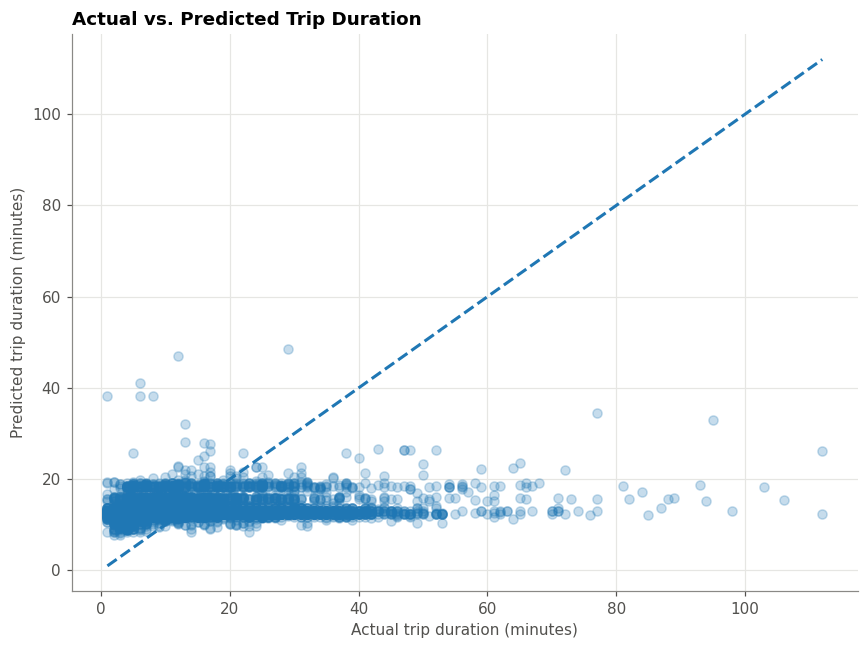

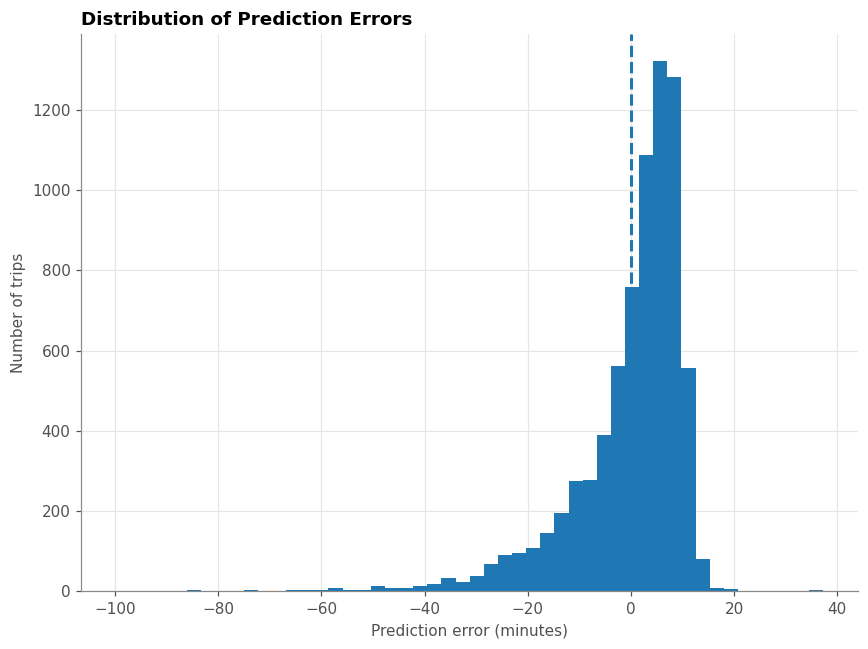

In [ ]:

# Make predictions on the validation set
y_val_pred = gbr_model.predict(X_val)

# Calculate metrics
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(mean_squared_error(y_val, y_val_pred))
r2 = r2_score(y_val, y_val_pred)

print(f"Validation MAE:  {mae:.2f} minutes")
print(f"Validation RMSE: {rmse:.2f} minutes")
print(f"Validation R²:   {r2:.4f}")

# 1. Actual vs. predicted trip duration
plt.figure(figsize=(8, 6))
plt.scatter(y_val, y_val_pred, alpha=0.25)

# Reference line: perfect predictions
plot_min = min(y_val.min(), y_val_pred.min())
plot_max = max(y_val.max(), y_val_pred.max())
plt.plot([plot_min, plot_max], [plot_min, plot_max], linestyle="--")

plt.xlabel("Actual trip duration (minutes)")
plt.ylabel("Predicted trip duration (minutes)")
plt.title("Actual vs. Predicted Trip Duration")
plt.tight_layout()
plt.show()

# 2. Distribution of prediction errors
# Positive error = model predicted too high
errors = np.asarray(y_val_pred) - np.asarray(y_val)

plt.figure(figsize=(8, 6))
plt.hist(errors, bins=50)
plt.axvline(0, linestyle="--")
plt.xlabel("Prediction error (minutes)")
plt.ylabel("Number of trips")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()


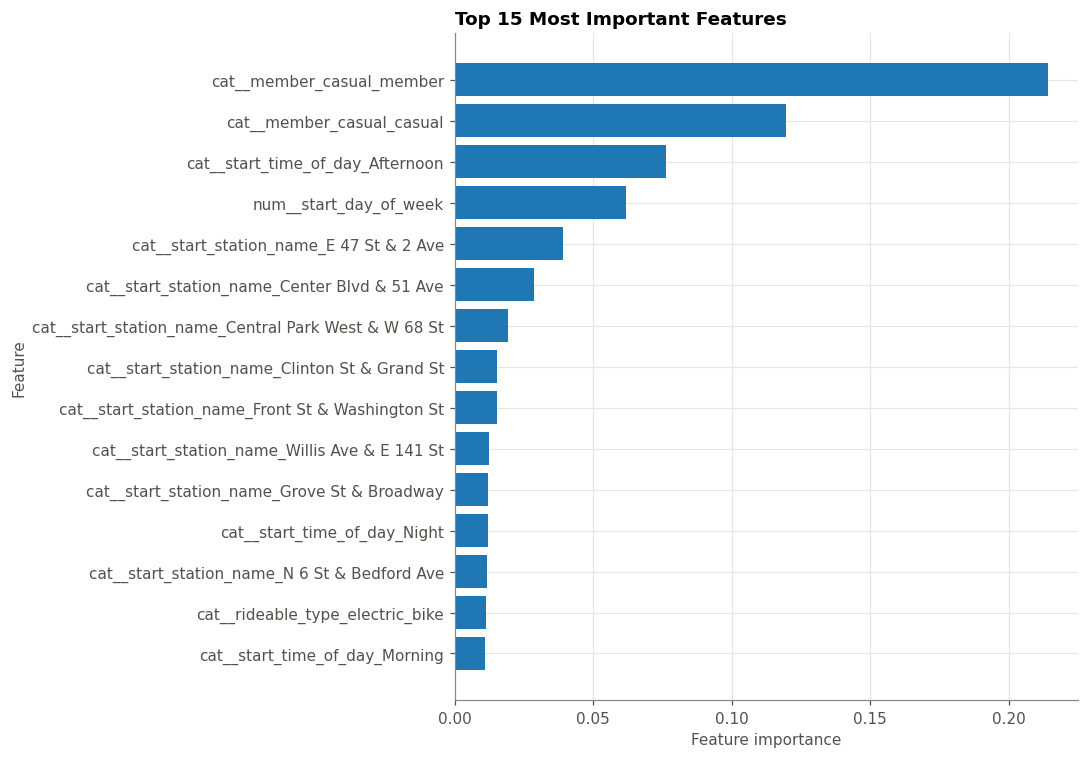

In [19]:

# 3. Feature importance from the fitted Gradient Boosting model
preprocessor = gbr_model.named_steps["preprocessor"]
regressor = gbr_model.named_steps["regressor"]

feature_names = preprocessor.get_feature_names_out()
importances = regressor.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False).head(15)

plt.figure(figsize=(10, 7))
plt.barh(importance_df["Feature"][::-1],
         importance_df["Importance"][::-1])
plt.xlabel("Feature importance")
plt.ylabel("Feature")
plt.title("Top 15 Most Important Features")
plt.tight_layout()
plt.show()
